<a href="https://colab.research.google.com/github/DeepFluxion/2026-_2_REDES_NEURAIS_DEEP_LEARNING/blob/main/notebooks/RNN/2026_2_Aula_07_10_26_RNN_LSTM_GRU_series_temporais_NLP%20(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Redes Neurais Recorrentes (RNN, LSTM, GRU): Séries Temporais e NLP

Notebook de apoio ao **Plano de Aula – Redes Neurais Recorrentes**. Cobre:

1. RNN — conceito, matemática e treinamento (séries temporais)
2. LSTM e GRU — conceito, matemática e treinamento (séries temporais)
3. Implementação em PyTorch com exemplos
4. RNN aplicada a Processamento de Linguagem Natural (NLP)
5. **Exercícios** com dados reais (ações, COVID-19, sentimento de texto) e **gabarito** ao final

**Pré-requisitos**: Python, PyTorch (tensores, `nn.Module`, `autograd`, `DataLoader`), Redes Densas e Redes Convolucionais.


## 0. Setup

Importações e seed para reprodutibilidade.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

print("PyTorch:", torch.__version__)


PyTorch: 2.13.0+cpu


## 1. RNN — Conceito, Matemática e Treinamento

### 1.1 Motivação

Redes densas e CNNs assumem entradas de tamanho fixo e, em geral, independência entre exemplos.
Séries temporais quebram essa suposição: cada observação depende das anteriores.

Uma **RNN** é uma rede densa que **reutiliza os mesmos pesos a cada passo de tempo**, com uma conexão
recorrente que funciona como memória: o neurônio recorrente recebe o dado do passo atual $x_t$ e o seu
próprio estado de saída do passo anterior $h_{t-1}$.

### 1.2 Equações

"Desenrolando" a rede no tempo, para cada passo $t$:


$$
h_t = \phi_h(x_t W_{xh} + h_{t-1} W_{hh} + b_h)
o_t = \phi_o(h_t W_{ho} + b_o)
$$

- Os pesos $W_{xh}$, $W_{hh}$, $W_{ho}$ e os bias são **compartilhados em todos os passos de tempo**
  (paralelo com o compartilhamento de pesos das CNNs, mas no eixo do tempo em vez do espaço).
- $\phi_h$ é tipicamente `tanh`; $\phi_o$ depende da tarefa (identidade para regressão, softmax para classificação).
- Em séries temporais, a entrada é organizada em janelas: um tensor 3D `(batch, seq_len, n_features)`.

### 1.3 Treinamento — Backpropagation Through Time (BPTT)

A RNN desenrolada é tratada como uma rede feedforward profunda (uma "cópia" por passo de tempo) e o
backprop comum é aplicado — técnica chamada **BPTT**. A perda total é a soma das perdas de cada passo de
tempo. O gradiente em relação a $W_{hh}$ envolve um produto de termos ao longo de todos os passos, o que
introduz o **problema do gradiente que explode/desaparece** conforme a sequência cresce — motivação
central para LSTM e GRU (seção 2). Na prática, usa-se também o **truncated BPTT** (limitar quantos passos
são retropropagados) por custo computacional.


### 1.4 Dados: série senoidal com ruído

Vamos usar, ao longo de todo o notebook, o mesmo dataset sintético (seno + ruído) como fio condutor para
comparar RNN, LSTM e GRU de forma justa.


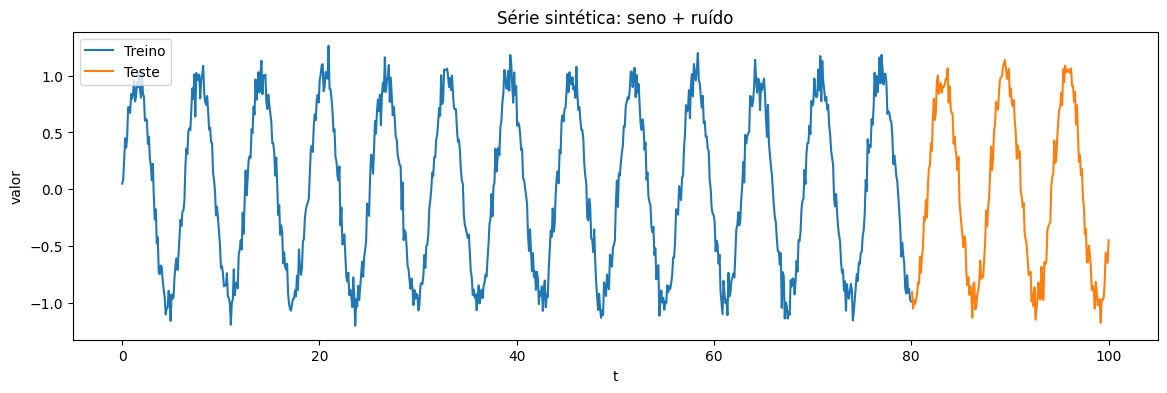

In [ ]:
t = np.linspace(0, 100, 1000)
series = np.sin(t) + np.random.normal(0, 0.1, size=len(t))

train_size = int(len(series) * 0.8)
train, test = series[:train_size], series[train_size:]

plt.figure(figsize=(14, 4))
plt.plot(t[:train_size], train, label="Treino")
plt.plot(t[train_size:], test, label="Teste")
plt.title("Série sintética: seno + ruído")
plt.xlabel("t")
plt.ylabel("valor")
plt.legend()
plt.show()


### 1.5 Janelamento (windowing)

Uma camada recorrente espera um tensor 3D `(batch, seq_len, n_features)`. A função `create_dataset`
transforma a série em pares (janela de entrada, próximo valor).


In [ ]:
def create_dataset(data, time_steps=10):
    X, y = [], []
    for i in range(len(data) - time_steps):
        X.append(data[i:i + time_steps])
        y.append(data[i + time_steps])
    return np.array(X), np.array(y)

TIME_STEPS = 10

X_train, y_train = create_dataset(train, TIME_STEPS)
X_test, y_test = create_dataset(test, TIME_STEPS)

# Formato (batch, seq_len, n_features) -> adiciona o eixo de features
X_train_t = torch.tensor(X_train, dtype=torch.float32).unsqueeze(-1)
y_train_t = torch.tensor(y_train, dtype=torch.float32).unsqueeze(-1)
X_test_t = torch.tensor(X_test, dtype=torch.float32).unsqueeze(-1)
y_test_t = torch.tensor(y_test, dtype=torch.float32).unsqueeze(-1)

print("X_train:", X_train_t.shape, " y_train:", y_train_t.shape)

train_dataset = TensorDataset(X_train_t, y_train_t)
# shuffle=False: em séries temporais a ordem importa!
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=False)


X_train: torch.Size([790, 10, 1])  y_train: torch.Size([790, 1])


### 1.6 Modelo `nn.RNN` e treinamento


Época   5 | Loss treino: 0.01612
Época  10 | Loss treino: 0.01525
Época  15 | Loss treino: 0.01472
Época  20 | Loss treino: 0.01440
Época  25 | Loss treino: 0.01422
Época  30 | Loss treino: 0.01417


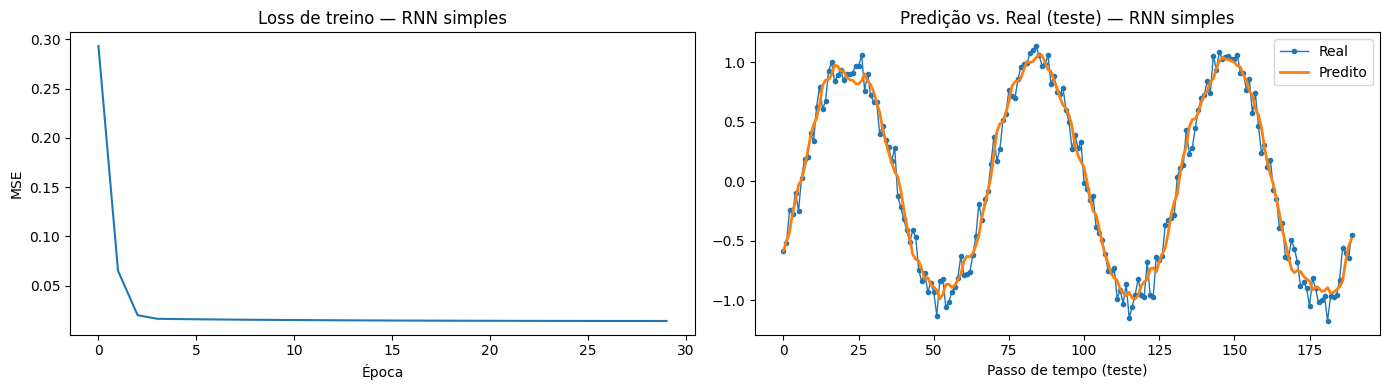

In [ ]:
class TimeSeriesRNN(nn.Module):
    def __init__(self, input_size=1, hidden_size=32, output_size=1):
        super().__init__()
        self.rnn = nn.RNN(input_size, hidden_size, batch_first=True)
        self.linear = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        out, _ = self.rnn(x)              # out: (batch, seq_len, hidden_size)
        return self.linear(out[:, -1, :]) # usa apenas o último passo de tempo


def train_model(model, loader, epochs=30, lr=1e-3, verbose_every=5):
    loss_fn = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    losses = []
    for epoch in range(epochs):
        epoch_loss = 0.0
        for seq, labels in loader:
            optimizer.zero_grad()
            y_pred = model(seq)
            loss = loss_fn(y_pred, labels)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
        avg_loss = epoch_loss / len(loader)
        losses.append(avg_loss)
        if (epoch + 1) % verbose_every == 0:
            print(f"Época {epoch + 1:3d} | Loss treino: {avg_loss:.5f}")
    return losses


def evaluate_and_plot(model, X_test_t, y_test_t, losses, title):
    model.eval()
    with torch.no_grad():
        y_pred = model(X_test_t).numpy()
    y_true = y_test_t.numpy()

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].plot(losses)
    axes[0].set_title(f"Loss de treino — {title}")
    axes[0].set_xlabel("Época")
    axes[0].set_ylabel("MSE")

    axes[1].plot(y_true, label="Real", marker=".", linewidth=1)
    axes[1].plot(y_pred, label="Predito", linewidth=2)
    axes[1].set_title(f"Predição vs. Real (teste) — {title}")
    axes[1].set_xlabel("Passo de tempo (teste)")
    axes[1].legend()

    plt.tight_layout()
    plt.show()
    return y_pred


model_rnn = TimeSeriesRNN()
rnn_losses = train_model(model_rnn, train_loader)
y_pred_rnn = evaluate_and_plot(model_rnn, X_test_t, y_test_t, rnn_losses, "RNN simples")


## 2. LSTM — Conceito, Matemática e Treinamento

### 2.1 O problema da memória de curto prazo

Em sequências longas, a RNN simples enfrenta dois obstáculos:

1. **Instabilidade dos gradientes** (explosão/desaparecimento).
2. **Amnésia**: a rede perde o rastro das primeiras entradas conforme a sequência avança.

A célula **LSTM** resolve isso separando o estado em dois vetores: o estado de longo prazo $c_t$ e o
estado de curto prazo $h_t$, controlados por três *gates* (portões).

### 2.2 Equações



$f_t = \sigma(x_t W_{xf} + h_{t-1} W_{hf} + b_f)$

$i_t = \sigma(x_t W_{xi} + h_{t-1} W_{hi} + b_i)$

$o_t = \sigma(x_t W_{xo} + h_{t-1} W_{ho} + b_o)$

$\tilde{c}_t = \tanh(x_t W_{xc} + h_{t-1} W_{hc} + b_c)$

$c_t = f_t \odot c_{t-1} + i_t \odot \tilde{c}_t$

$h_t = o_t \odot \tanh(c_t)$

- **Forget gate** ($f_t$): decide o que apagar do estado de longo prazo.
- **Input gate** ($i_t$): decide o que adicionar ao estado de longo prazo (candidato $\tilde{c}_t$).
- **Output gate** ($o_t$): decide o que do estado de longo prazo é lido como saída no passo atual.
- $\odot$ é o produto elemento-a-elemento (Hadamard). A soma $f_t \odot c_{t-1} + i_t \odot \tilde{c}_t$
  cria um caminho quase linear para o gradiente fluir por muitos passos sem desaparecer — a ideia central
  por trás da LSTM.

### 2.3 Implementação e treinamento

Mesma base senoidal da seção 1, agora com `nn.LSTM` (128 unidades ocultas).


Época   5 | Loss treino: 0.01485
Época  10 | Loss treino: 0.01458
Época  15 | Loss treino: 0.01463
Época  20 | Loss treino: 0.01450
Época  25 | Loss treino: 0.01440
Época  30 | Loss treino: 0.01432


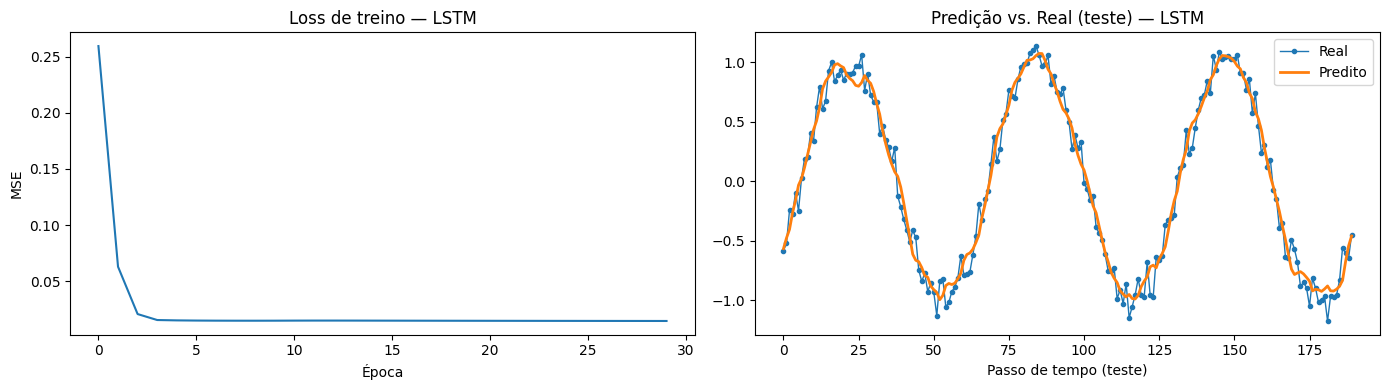

In [ ]:
class TimeSeriesLSTM(nn.Module):
    def __init__(self, input_size=1, hidden_layer_size=128, output_size=1):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_layer_size, batch_first=True)
        self.linear = nn.Linear(hidden_layer_size, output_size)

    def forward(self, input_seq):
        lstm_out, _ = self.lstm(input_seq)
        return self.linear(lstm_out[:, -1, :])


model_lstm = TimeSeriesLSTM()
lstm_losses = train_model(model_lstm, train_loader)
y_pred_lstm = evaluate_and_plot(model_lstm, X_test_t, y_test_t, lstm_losses, "LSTM")


## 3. GRU — Conceito, Matemática e Treinamento

### 3.1 GRU como simplificação da LSTM

A **GRU** (Cho et al., 2014) simplifica a LSTM unificando os estados $c_t$ e $h_t$ em um único vetor
$h_t$, com apenas dois gates. Costuma ter desempenho comparável à LSTM com menos parâmetros, o que pode
acelerar o treinamento.

### 3.2 Equações


$z_t = \sigma(x_t W_{xz} + h_{t-1} W_{hz} + b_z)$  

$r_t = \sigma(x_t W_{xr} + h_{t-1} W_{hr} + b_r)$  

$\tilde{h}_t = \tanh(x_t W_{xh} + (r_t \odot h_{t-1}) W_{hh} + b_h)$   

$h_t = (1 - z_t) \odot h_{t-1} + z_t \odot \tilde{h}_t$

- **Update gate** ($z_t$): funde os papéis do forget e do input gate da LSTM — se decide reter memória
  antiga, automaticamente reduz a entrada de memória nova.
- **Reset gate** ($r_t$): substitui o output gate, controlando quanto do estado anterior é usado para
  calcular o candidato $\tilde{h}_t$.

### 3.3 Implementação, treinamento e comparação com a LSTM


Época   5 | Loss treino: 0.01447
Época  10 | Loss treino: 0.01455
Época  15 | Loss treino: 0.01447
Época  20 | Loss treino: 0.01440
Época  25 | Loss treino: 0.01434
Época  30 | Loss treino: 0.01430


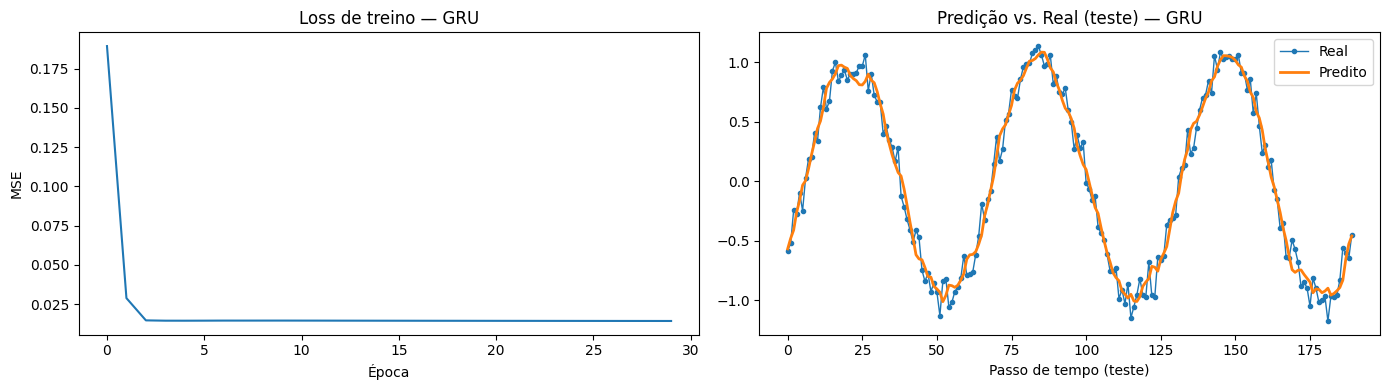

In [ ]:
class TimeSeriesGRU(nn.Module):
    def __init__(self, input_size=1, hidden_layer_size=128, output_size=1):
        super().__init__()
        self.gru = nn.GRU(input_size, hidden_layer_size, batch_first=True)
        self.linear = nn.Linear(hidden_layer_size, output_size)

    def forward(self, input_seq):
        gru_out, _ = self.gru(input_seq)
        return self.linear(gru_out[:, -1, :])


model_gru = TimeSeriesGRU()
gru_losses = train_model(model_gru, train_loader)
y_pred_gru = evaluate_and_plot(model_gru, X_test_t, y_test_t, gru_losses, "GRU")


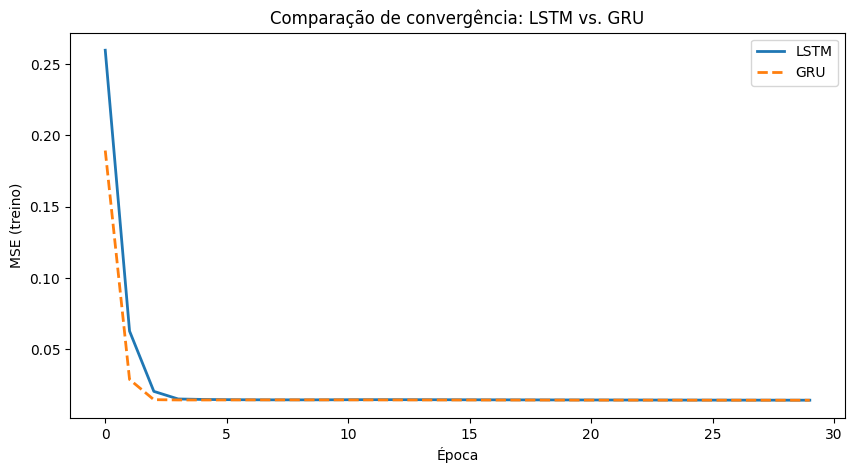

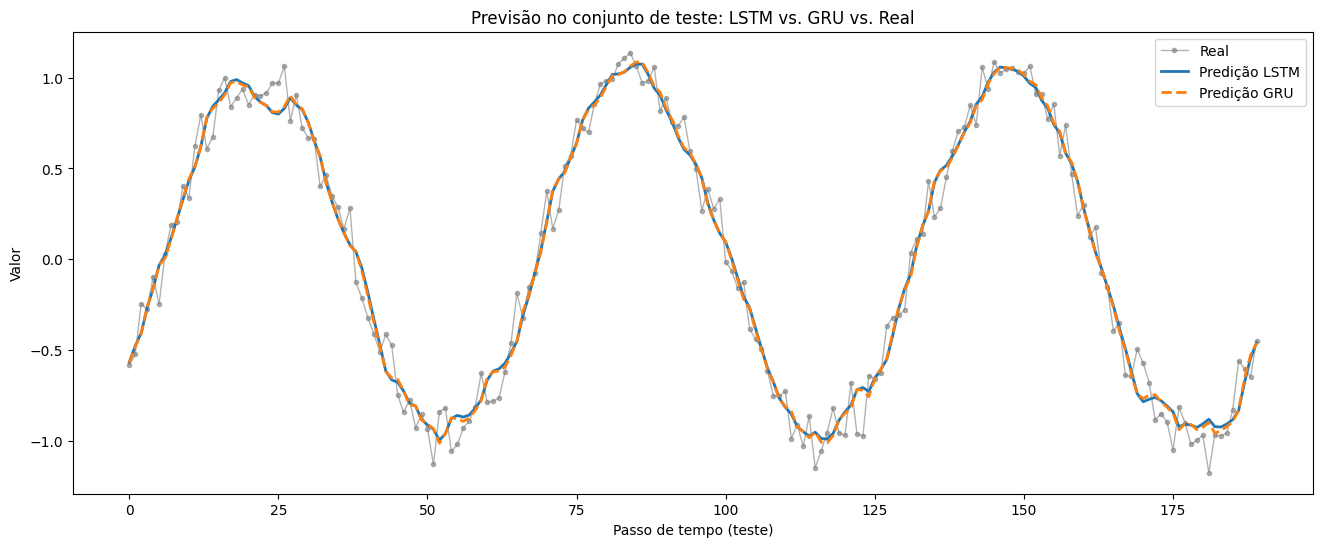

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(lstm_losses, label="LSTM", linewidth=2)
plt.plot(gru_losses, label="GRU", linewidth=2, linestyle="--")
plt.title("Comparação de convergência: LSTM vs. GRU")
plt.xlabel("Época")
plt.ylabel("MSE (treino)")
plt.legend()
plt.show()

plt.figure(figsize=(16, 6))
plt.plot(y_test, label="Real", color="grey", alpha=0.6, marker=".", linewidth=1)
plt.plot(y_pred_lstm, label="Predição LSTM", linewidth=2)
plt.plot(y_pred_gru, label="Predição GRU", linewidth=2, linestyle="--")
plt.title("Previsão no conjunto de teste: LSTM vs. GRU vs. Real")
plt.xlabel("Passo de tempo (teste)")
plt.ylabel("Valor")
plt.legend()
plt.show()


### 3.4 Baseline clássico: ARMA

Antes de assumir que Deep Learning é a melhor solução, é boa prática estabelecer uma linha de base com um
método estatístico clássico. O **ARMA** (AutoRegressive Moving Average) combina:

1. **Componente autorregressivo (AR, ordem $p$)**: soma ponderada de valores passados da própria série.
2. **Componente de média móvel (MA, ordem $q$)**: corrige a previsão usando os erros das previsões recentes.

Na biblioteca `statsmodels`, o ARMA é obtido com a classe `ARIMA` fixando o hiperparâmetro de integração
`d=0`. Usamos a predição "um passo à frente" (`dynamic=False`), para manter a comparação justa com o
janelamento das redes recorrentes.


In [ ]:
#! pip install statsmodels

C:\Users\domin\anaconda3\envs\kernelPAD\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


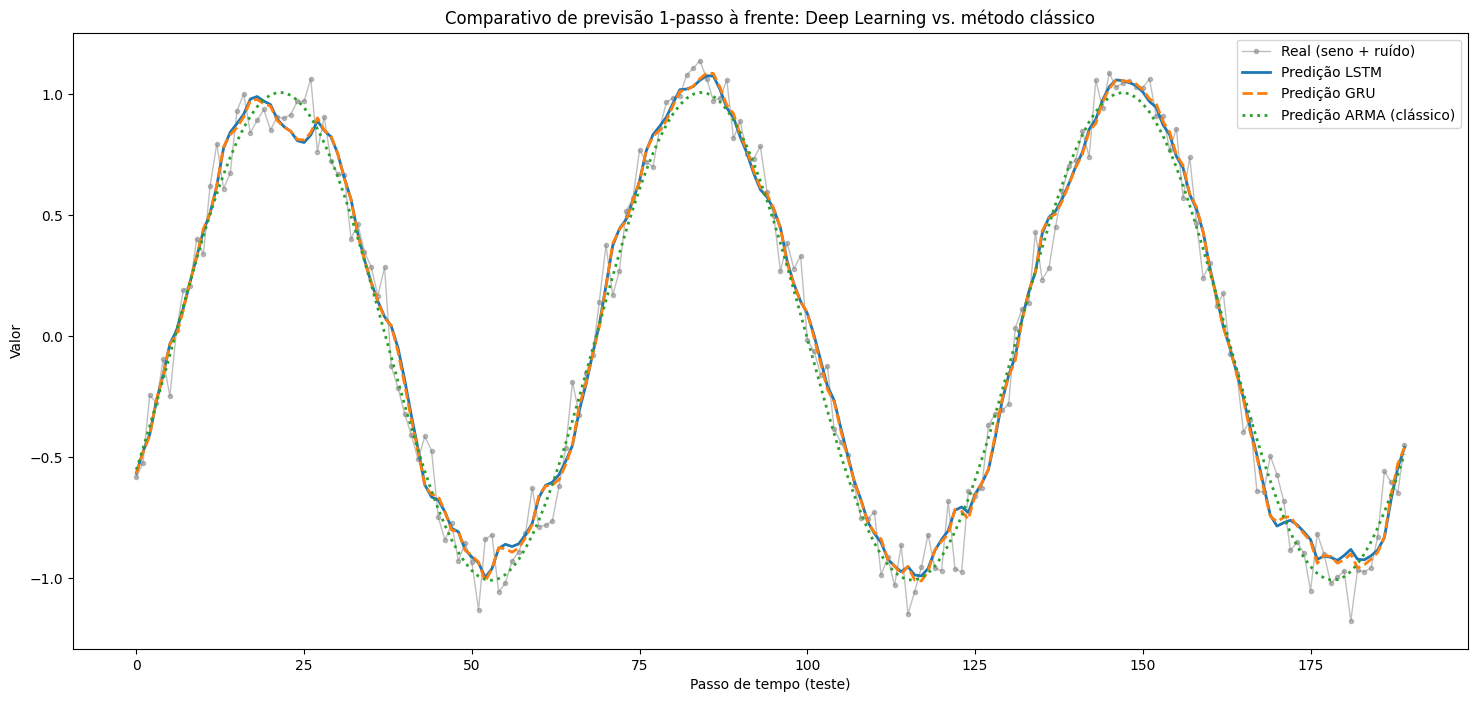

In [ ]:
from statsmodels.tsa.arima.model import ARIMA

series_pd = pd.Series(series)
train_pd, test_pd = series_pd[:train_size], series_pd[train_size:]

arma_model = ARIMA(train_pd, order=(2, 0, 2))
arma_fit = arma_model.fit()

arma_pred = arma_fit.predict(start=train_size, end=len(series_pd) - 1, dynamic=False)
# Alinhar com o corte de TIME_STEPS perdido no janelamento das redes recorrentes
arma_pred_np = arma_pred.values[TIME_STEPS:]

plt.figure(figsize=(18, 8))
plt.plot(y_test, label="Real (seno + ruído)", color="grey", alpha=0.5, marker=".", linewidth=1)
plt.plot(y_pred_lstm, label="Predição LSTM", linewidth=2)
plt.plot(y_pred_gru, label="Predição GRU", linewidth=2, linestyle="--")
plt.plot(arma_pred_np, label="Predição ARMA (clássico)", linewidth=2, linestyle=":")
plt.title("Comparativo de previsão 1-passo à frente: Deep Learning vs. método clássico")
plt.xlabel("Passo de tempo (teste)")
plt.ylabel("Valor")
plt.legend(loc="upper right")
plt.show()


**Conclusão do comparativo.** Em séries estacionárias e relativamente simples como esta (seno +
ruído), um modelo clássico como o ARMA pode ser tão competitivo quanto — ou até melhor que — arquiteturas
de Deep Learning. A vantagem de LSTM/GRU aparece de fato em sequências mais complexas, multidimensionais
e com não linearidades que uma soma ponderada não captura (ex.: texto, dados biológicos, múltiplas
features temporais simultâneas). **Regra prática**: comece sempre com métodos clássicos; só justifique
Deep Learning se eles atingirem um teto de desempenho.


## 4. Consolidação: o pipeline de séries temporais

Repare que os três modelos (RNN, LSTM, GRU) compartilham exatamente o mesmo pipeline — só a célula
recorrente muda:

```
dados brutos (1D)
   -> janelamento (create_dataset): pares (janela, próximo valor)
   -> tensor 3D (batch, seq_len, n_features)
   -> DataLoader(shuffle=False)
   -> modelo (nn.RNN / nn.LSTM / nn.GRU + Linear)
   -> treino (Adam + MSELoss)
   -> avaliação: loss numérica + inspeção visual (real vs. predito)
```

Esse é o pipeline que você vai reaplicar nos **Exercícios** (seção 7), trocando apenas a fonte de dados.


## 5. RNN Aplicada a NLP

### 5.1 De números a tokens

Até aqui, a entrada da RNN era um valor numérico contínuo por passo de tempo. Em NLP, o "passo de tempo"
é uma palavra (ou caractere/subpalavra), e o primeiro problema é representá-la numericamente:

1. **Tokenização**: quebrar o texto em unidades e construir um vocabulário.
2. **Embedding**: em vez de one-hot (esparso, sem noção de semelhança semântica), usar `nn.Embedding`,
   uma tabela de lookup treinável que mapeia cada token para um vetor denso.

### 5.2 Arquitetura para classificação de texto

`Embedding → LSTM/GRU → (último estado oculto) → Linear → (Sigmoid/Softmax)`

Diferença-chave em relação a séries temporais: a saída de interesse normalmente é apenas o **último
estado oculto** (resumo de toda a sequência) — mesmo padrão de "pegar o último passo de tempo" já usado
nas seções 1–3, mas agora aplicado ao estado oculto em vez da sequência de saída completa.

### 5.3 Exemplo mínimo em PyTorch (dataset sintético)


In [ ]:
sentences = [
    ("eu adorei esse filme", 1),
    ("que produto incrivel", 1),
    ("recomendo demais esse curso", 1),
    ("a aula foi otima hoje", 1),
    ("gostei muito do atendimento", 1),
    ("experiencia maravilhosa de compra", 1),
    ("o resultado ficou excelente", 1),
    ("estou muito feliz com a entrega", 1),
    ("pessimo atendimento hoje", 0),
    ("nao gostei nada disso", 0),
    ("experiencia horrivel de compra", 0),
    ("a aula foi muito ruim", 0),
    ("o produto veio quebrado", 0),
    ("estou muito decepcionado com o servico", 0),
    ("nunca mais compro aqui", 0),
    ("o resultado ficou terrivel", 0),
]

# --- tokenização simples e vocabulário ---
def tokenize(text):
    return text.lower().split()

vocab = {"<pad>": 0, "<unk>": 1}
for text, _ in sentences:
    for tok in tokenize(text):
        if tok not in vocab:
            vocab[tok] = len(vocab)

def encode(text, vocab, max_len):
    ids = [vocab.get(tok, vocab["<unk>"]) for tok in tokenize(text)]
    ids = ids[:max_len] + [vocab["<pad>"]] * max(0, max_len - len(ids))
    return ids

MAX_LEN = max(len(tokenize(t)) for t, _ in sentences)

X_nlp = torch.tensor([encode(t, vocab, MAX_LEN) for t, _ in sentences], dtype=torch.long)
y_nlp = torch.tensor([label for _, label in sentences], dtype=torch.long)

print("Vocabulário:", len(vocab), "tokens")
print("X_nlp:", X_nlp.shape, " y_nlp:", y_nlp.shape)


Vocabulário: 48 tokens
X_nlp: torch.Size([16, 6])  y_nlp: torch.Size([16])


In [ ]:
class TextClassifierLSTM(nn.Module):
    def __init__(self, vocab_size, embed_dim=16, hidden_size=32, num_classes=2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm = nn.LSTM(embed_dim, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        embedded = self.embedding(x)            # (batch, seq_len, embed_dim)
        _, (h_n, _) = self.lstm(embedded)        # h_n: (1, batch, hidden_size)
        return self.fc(h_n.squeeze(0))           # (batch, num_classes)


text_model = TextClassifierLSTM(vocab_size=len(vocab))
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(text_model.parameters(), lr=1e-2)

for epoch in range(60):
    optimizer.zero_grad()
    logits = text_model(X_nlp)
    loss = loss_fn(logits, y_nlp)
    loss.backward()
    optimizer.step()
    if (epoch + 1) % 10 == 0:
        acc = (logits.argmax(dim=1) == y_nlp).float().mean().item()
        print(f"Época {epoch + 1:3d} | Loss: {loss.item():.4f} | Acurácia (treino): {acc:.2%}")

# Teste manual com frases novas
novas = ["adorei o atendimento", "que experiencia terrivel", "recomendo muito", 'detestei o atendimento']
with torch.no_grad():
    x_novas = torch.tensor([encode(t, vocab, MAX_LEN) for t in novas], dtype=torch.long)
    preds = text_model(x_novas).argmax(dim=1)
for t, p in zip(novas, preds):
    print(f"'{t}' -> {'positivo' if p.item() == 1 else 'negativo'}")


Época  10 | Loss: 0.3312 | Acurácia (treino): 87.50%
Época  20 | Loss: 0.0034 | Acurácia (treino): 100.00%
Época  30 | Loss: 0.0001 | Acurácia (treino): 100.00%
Época  40 | Loss: 0.0000 | Acurácia (treino): 100.00%
Época  50 | Loss: 0.0000 | Acurácia (treino): 100.00%
Época  60 | Loss: 0.0000 | Acurácia (treino): 100.00%
'adorei o atendimento' -> positivo
'que experiencia terrivel' -> positivo
'recomendo muito' -> positivo
'detestei o atendimento' -> negativo


### 5.4 Extensões (não implementadas aqui, apenas conceito)

- **Padding e comprimento variável**: em datasets reais, `nn.utils.rnn.pack_padded_sequence` /
  `pad_packed_sequence` evitam que o modelo processe posições de padding como se fossem conteúdo real.
- **RNN Bidirecional** (`nn.LSTM(..., bidirectional=True)`): processa a sequência também de trás para
  frente — útil quando o contexto futuro da frase importa (ex.: preencher uma lacuna no meio do texto).
- **Geração de texto (char-RNN)**: mesma arquitetura, mas prevendo o próximo caractere/token a cada passo,
  de forma autoregressiva.
- **Próximo passo da disciplina**: mecanismo de **atenção** e a arquitetura **Transformer**, que substitui
  a recorrência inteiramente por self-attention.
